# Exploratory Data Analysis Lab (BCSE331P) — Python Implementation
**Name:** E Revanth | **Reg No:** 23BDS0027 | **Dataset:** Fishing.csv


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
fishing = pd.read_csv("Fishing.csv")
print(fishing.shape)

(1182, 13)


# Assessment 1 — Data Frames & Data Transformations

## Q1. Dataframe operations (append, concat, merge, joins)

In [ ]:
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": ["Laptop","Mouse","Keyboard","Monitor","Printer","Speaker","Webcam","Router","Scanner","HardDisk"],
    "Price": [55000,800,1500,12000,9000,2500,1800,3500,7000,5000]})
dataframe2 = pd.DataFrame({
    "ProductID": range(101, 111),
    "Company_Location": ["Chennai","Mumbai","Delhi","Bangalore","Hyderabad","Pune","Kolkata","Ahmedabad","Jaipur","Coimbatore"]})
dataframe3 = pd.DataFrame({
    "ProductID": range(111, 121),
    "NameofProd": ["SSD","PenDrive","Projector","Tablet","Camera","SmartWatch","Microphone","Headphone","UPS","PowerBank"],
    "Price": [4500,900,30000,22000,45000,6000,3500,2800,5000,1500]})
print(dataframe1, dataframe2, dataframe3, sep="\n\n")

   ProductID NameofProd  Price
0        101     Laptop  55000
1        102      Mouse    800
2        103   Keyboard   1500
3        104    Monitor  12000
4        105    Printer   9000
5        106    Speaker   2500
6        107     Webcam   1800
7        108     Router   3500
8        109    Scanner   7000
9        110   HardDisk   5000

   ProductID Company_Location
0        101          Chennai
1        102           Mumbai
2        103            Delhi
3        104        Bangalore
4        105        Hyderabad
5        106             Pune
6        107          Kolkata
7        108        Ahmedabad
8        109           Jaipur
9        110       Coimbatore

   ProductID  NameofProd  Price
0        111         SSD   4500
1        112    PenDrive    900
2        113   Projector  30000
3        114      Tablet  22000
4        115      Camera  45000
5        116  SmartWatch   6000
6        117  Microphone   3500
7        118   Headphone   2800
8        119         UPS   5000
9      

In [ ]:
# 1. Append df1 and df3 (rbind)
append_df = pd.concat([dataframe1, dataframe3], ignore_index=True); print(append_df)
# 2. Concatenate column-wise (cbind)
concat_df = pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1); print(concat_df)
# 3. Merge on ProductID
merged_df = pd.merge(dataframe1, dataframe2, on="ProductID"); print(merged_df)
# 4. Joins
for how in ["inner","left","right","outer"]:
    print(f"\n{how.upper()} JOIN"); print(pd.merge(dataframe1, dataframe2, on="ProductID", how=how))

    ProductID  NameofProd  Price
0         101      Laptop  55000
1         102       Mouse    800
2         103    Keyboard   1500
3         104     Monitor  12000
4         105     Printer   9000
5         106     Speaker   2500
6         107      Webcam   1800
7         108      Router   3500
8         109     Scanner   7000
9         110    HardDisk   5000
10        111         SSD   4500
11        112    PenDrive    900
12        113   Projector  30000
13        114      Tablet  22000
14        115      Camera  45000
15        116  SmartWatch   6000
16        117  Microphone   3500
17        118   Headphone   2800
18        119         UPS   5000
19        120   PowerBank   1500
   ProductID NameofProd  Price Company_Location
0        101     Laptop  55000          Chennai
1        102      Mouse    800           Mumbai
2        103   Keyboard   1500            Delhi
3        104    Monitor  12000        Bangalore
4        105    Printer   9000        Hyderabad
5        106    Spe

## Q2. Data transformations

In [ ]:
Revanth = np.array([27, 15, 32, 48, 56, 72, 84, 96, 110, 125], dtype=float)  # first value = last 4 digits of reg no (0027)
print("Original:", Revanth)
def normalize(x, new_min, new_max):
    return (x - x.min()) / (x.max() - x.min()) * (new_max - new_min) + new_min
print("[-3,+3]  :", normalize(Revanth, -3, 3).round(4))
print("[-1,+1]  :", normalize(Revanth, -1, 1).round(4))
print("[0,1]    :", normalize(Revanth, 0, 1).round(4))
z_score = (Revanth - Revanth.mean()) / Revanth.std(ddof=1)
print("Z-score  :", z_score.round(4))
j = len(str(int(np.abs(Revanth).max())))
print("Decimal scaling (j=%d):" % j, Revanth / 10**j)

Original: [ 27.  15.  32.  48.  56.  72.  84.  96. 110. 125.]
[-3,+3]  : [-2.3455 -3.     -2.0727 -1.2    -0.7636  0.1091  0.7636  1.4182  2.1818
  3.    ]
[-1,+1]  : [-0.7818 -1.     -0.6909 -0.4    -0.2545  0.0364  0.2545  0.4727  0.7273
  1.    ]
[0,1]    : [0.1091 0.     0.1545 0.3    0.3727 0.5182 0.6273 0.7364 0.8636 1.    ]
Z-score  : [-1.0652 -1.3888 -0.9303 -0.4989 -0.2831  0.1483  0.4719  0.7955  1.173
  1.5775]
Decimal scaling (j=3): [0.027 0.015 0.032 0.048 0.056 0.072 0.084 0.096 0.11  0.125]


# Assessment 2 — Data Exploration & Missing Values

In [ ]:
print(fishing.head(10)); print(fishing.tail(10))
print("Rows:", fishing.shape[0], "Columns:", fishing.shape[1])
print(list(fishing.columns)); print(fishing.dtypes)
print(fishing.describe(include="all").T)
print("Missing per column:\n", fishing.isna().sum()); print("Total missing:", fishing.isna().sum().sum())

   rownames     mode    price   catch   pbeach    ppier    pboat  pcharter  cbeach   cpier   cboat  ccharter     income
0         1  charter  182.930  0.5391  157.930  157.930  157.930   182.930  0.0678  0.0503  0.2601    0.5391  7083.3317
1         2  charter   34.534  0.4671   15.114   15.114   10.534    34.534  0.1049  0.0451  0.1574    0.4671  1249.9998
2         3     boat   24.334  0.2413  161.874  161.874   24.334    59.334  0.5333  0.4522  0.2413    1.0266  3749.9999
3         4     pier   15.134  0.0789   15.134   15.134   55.930    84.930  0.0678  0.0789  0.1643    0.5391  2083.3332
4         5     boat   41.514  0.1082  106.930  106.930   41.514    71.014  0.0678  0.0503  0.1082    0.3240  4583.3320
5         6  charter   63.934  0.3975  192.474  192.474   28.934    63.934  0.5333  0.4522  0.1665    0.3975  4583.3320
6         7    beach   51.934  0.0678   51.934   51.934  191.930   220.930  0.0678  0.0789  0.1643    0.5391  8750.0010
7         8  charter   56.714  0.0209   

The dataset has no missing values, so a working copy `fish_na` with random NAs (fixed seed) is created to demonstrate the techniques.

In [ ]:
rng = np.random.default_rng(123)
fish_na = fishing.copy()
fish_na.loc[rng.choice(len(fish_na), 15, replace=False), "income"] = np.nan
fish_na.loc[rng.choice(len(fish_na), 10, replace=False), "catch"]  = np.nan
fish_na.loc[rng.choice(len(fish_na), 8,  replace=False), "price"]  = np.nan
fish_na.loc[rng.choice(len(fish_na), 6,  replace=False), "mode"]   = np.nan
print(fish_na.isna().sum())
# Q11 rows with at least one NA
missing_rows = fish_na[fish_na.isna().any(axis=1)]
print("Rows with >=1 NA:", len(missing_rows)); print(missing_rows[["rownames","mode","price","catch","income"]].head(10))
# Q12 drop rows
cleaned_df = fish_na.dropna(); print("Before:", len(fish_na), "After:", len(cleaned_df))
# Q13 mean, Q14 median, Q15 mode
df_mean = fish_na.copy(); df_mean["income"] = df_mean["income"].fillna(df_mean["income"].mean())
df_median = fish_na.copy(); df_median["catch"] = df_median["catch"].fillna(df_median["catch"].median())
df_mode = fish_na.copy(); df_mode["mode"] = df_mode["mode"].fillna(df_mode["mode"].mode()[0])
print("NAs after mean/median/mode:", df_mean["income"].isna().sum(), df_median["catch"].isna().sum(), df_mode["mode"].isna().sum())
# Q16 forward fill, Q17 backward fill
df_ffill = fish_na.copy(); df_ffill["price"] = df_ffill["price"].ffill()
df_bfill = fish_na.copy(); df_bfill["catch"] = df_bfill["catch"].bfill()
print("NAs after ffill/bfill:", df_ffill["price"].isna().sum(), df_bfill["catch"].isna().sum())
# Q18 constant
df_const = fish_na.copy(); df_const["mode"] = df_const["mode"].fillna("Unknown")
num_cols = df_const.select_dtypes("number").columns; df_const[num_cols] = df_const[num_cols].fillna(0)
print("Remaining NAs:", df_const.isna().sum().sum())

rownames     0
mode         6
price        8
catch       10
pbeach       0
ppier        0
pboat        0
pcharter     0
cbeach       0
cpier        0
cboat        0
ccharter     0
income      15
dtype: int64
Rows with >=1 NA: 38
     rownames     mode    price   catch     income
17         18     pier      NaN  0.0079  2916.6666
18         19     boat   11.322  0.0361        NaN
63         64     boat    9.522  0.1574        NaN
91         92  charter      NaN  0.4671  5416.6667
169       170  charter      NaN  0.5391  4583.3320
174       175  charter   70.972     NaN  3749.9999
207       208     boat   47.804  0.1574        NaN
216       217    beach      NaN  0.0678        NaN
223       224      NaN  139.704  0.1648  4583.3320
240       241      NaN    9.522  0.0503  3749.9999
Before: 1182 After: 1144
NAs after mean/median/mode: 0 0 0
NAs after ffill/bfill: 0 0
Remaining NAs: 0


In [ ]:
# Q19 duplicates, Q20 factors, Q21 rename, Q22 derived columns
print("Duplicates:", fishing.duplicated().sum()); df_no_dups = fishing.drop_duplicates()
f2 = fishing.copy(); f2["mode"] = f2["mode"].astype("category"); print(f2["mode"].cat.categories.tolist(), f2["mode"].value_counts().to_dict())
f2 = f2.rename(columns={"rownames":"id","mode":"fishing_mode","catch":"catch_rate"})
f2["income_group"] = np.where(f2["income"] < 3000, "Low", np.where(f2["income"] >= 7000, "High", "Medium"))
f2["cost_per_catch"] = (f2["price"] / f2["catch_rate"]).round(2)
print(f2[["id","fishing_mode","price","catch_rate","income","income_group","cost_per_catch"]].head(10))
print(f2["income_group"].value_counts())

Duplicates: 0
['beach', 'boat', 'charter', 'pier'] {'charter': 452, 'boat': 418, 'pier': 178, 'beach': 134}
   id fishing_mode    price  catch_rate     income income_group  cost_per_catch
0   1      charter  182.930      0.5391  7083.3317         High          339.32
1   2      charter   34.534      0.4671  1249.9998          Low           73.93
2   3         boat   24.334      0.2413  3749.9999       Medium          100.85
3   4         pier   15.134      0.0789  2083.3332          Low          191.81
4   5         boat   41.514      0.1082  4583.3320       Medium          383.68
5   6      charter   63.934      0.3975  4583.3320       Medium          160.84
6   7        beach   51.934      0.0678  8750.0010         High          765.99
7   8      charter   56.714      0.0209  2083.3332          Low         2713.59
8   9         boat   34.914      0.0233  3749.9999       Medium         1498.45
9  10         boat   28.314      0.0233  2916.6666          Low         1215.19
income_group

In [ ]:
# Q24-Q28 descriptive statistics
print("Min/Max price:", fishing["price"].min(), fishing["price"].max())
print("Range:", fishing["price"].max() - fishing["price"].min())
print("Variance:", fishing["price"].var(), " SD:", fishing["price"].std(), " IQR:", stats.iqr(fishing["price"]))
print(fishing["price"].quantile([0,.25,.5,.75,1]))

Min/Max price: 1.29 666.11
Range: 664.82
Variance: 2897.665639785977  SD: 53.829969717490805  IQR: 51.64300000000001
0.00      1.290
0.25     15.870
0.50     37.896
0.75     67.513
1.00    666.110
Name: price, dtype: float64


# Assessment 3 — Data Cleaning & Univariate Visualisation

In [ ]:
# Q1-Q4 build working copy with NAs, a sparse column and duplicates (as in the R lab)
rng = np.random.default_rng(2026)
fish = fishing.copy()
for col, n in [("income",15),("catch",10),("price",8),("mode",6)]:
    fish.loc[rng.choice(len(fish), n, replace=False), col] = np.nan
fish["licence_type"] = pd.Series([np.nan]*len(fish), dtype=object)
idx = rng.choice(len(fish), 250, replace=False)
fish.loc[idx, "licence_type"] = rng.choice(["Annual","Daily"], 250)
fish = pd.concat([fish, fish.sample(5, random_state=1)], ignore_index=True)
print(fish.shape, "| total NAs:", fish.isna().sum().sum())
print("Rows with >=1 NA:", fish.isna().any(axis=1).sum())

(1187, 14) | total NAs: 975
Rows with >=1 NA: 939


In [ ]:
# Q5 drop columns with >70% missing
na_pct = fish.isna().mean()*100; print(na_pct.round(2))
fish = fish.loc[:, fish.isna().mean() <= 0.70]; print(list(fish.columns))
# Q6 mean, Q7 median, Q8 mode
fish["income"] = fish["income"].fillna(fish["income"].mean())
fish["catch"]  = fish["catch"].fillna(fish["catch"].median())
fish["mode"]   = fish["mode"].fillna(fish["mode"].mode()[0])
fish["price"]  = fish["price"].fillna(fish["price"].median())
print("NAs left:", fish.isna().sum().sum())
# Q9-10 duplicates
print("Duplicates:", fish.duplicated().sum()); fish_clean = fish.drop_duplicates().copy(); print("Rows now:", len(fish_clean))
# Q11-13 dtypes, factors, case
print(fish_clean.dtypes.head(4)); fish_clean["mode"] = fish_clean["mode"].astype("category")
fish_clean["mode_lower"] = fish_clean["mode"].astype(str).str.lower(); fish_clean["mode_upper"] = fish_clean["mode"].astype(str).str.upper()
print(fish_clean[["mode","mode_lower","mode_upper"]].head(6))

rownames         0.00
mode             0.51
price            0.67
catch            0.84
pbeach           0.00
ppier            0.00
pboat            0.00
pcharter         0.00
cbeach           0.00
cpier            0.00
cboat            0.00
ccharter         0.00
income           1.26
licence_type    78.85
dtype: float64
['rownames', 'mode', 'price', 'catch', 'pbeach', 'ppier', 'pboat', 'pcharter', 'cbeach', 'cpier', 'cboat', 'ccharter', 'income']
NAs left: 0


Duplicates: 5
Rows now: 1182
rownames      int64
mode            str
price       float64
catch       float64
dtype: object
      mode mode_lower mode_upper
0  charter    charter    CHARTER
1  charter    charter    CHARTER
2     boat       boat       BOAT
3     pier       pier       PIER
4     boat       boat       BOAT
5  charter    charter    CHARTER


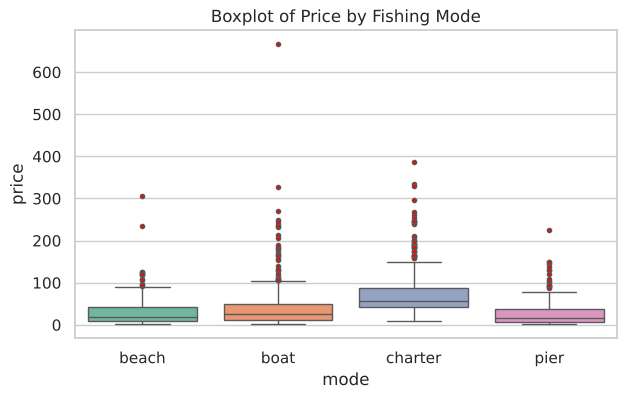

Q1=15.87 Q3=66.86 IQR=50.99 bounds=(-60.62, 143.36)
Outliers: 69
Rows before/after extreme-outlier removal: 1182 1158
count    1158.000000
mean       47.207225
std        40.536766
min         1.290000
25%        15.870000
50%        37.883000
75%        63.998000
max       213.860000
Name: price, dtype: float64


In [ ]:
# Q14 boxplot, Q15 IQR outliers, Q16 extreme outliers
plt.figure(figsize=(7,4)); sns.boxplot(data=fish_clean, x="mode", y="price", palette="Set2", flierprops=dict(markerfacecolor="red", markersize=3))
plt.title("Boxplot of Price by Fishing Mode"); plt.show()
Q1, Q3 = fish_clean["price"].quantile([.25,.75]); IQRv = Q3-Q1
lower, upper = Q1-1.5*IQRv, Q3+1.5*IQRv
print(f"Q1={Q1:.2f} Q3={Q3:.2f} IQR={IQRv:.2f} bounds=({lower:.2f}, {upper:.2f})")
outliers = fish_clean[(fish_clean.price<lower)|(fish_clean.price>upper)]; print("Outliers:", len(outliers))
ext_low, ext_high = Q1-3*IQRv, Q3+3*IQRv
fish_no_out = fish_clean[fish_clean.price.between(ext_low, ext_high)].copy()
print("Rows before/after extreme-outlier removal:", len(fish_clean), len(fish_no_out)); print(fish_no_out.price.describe())

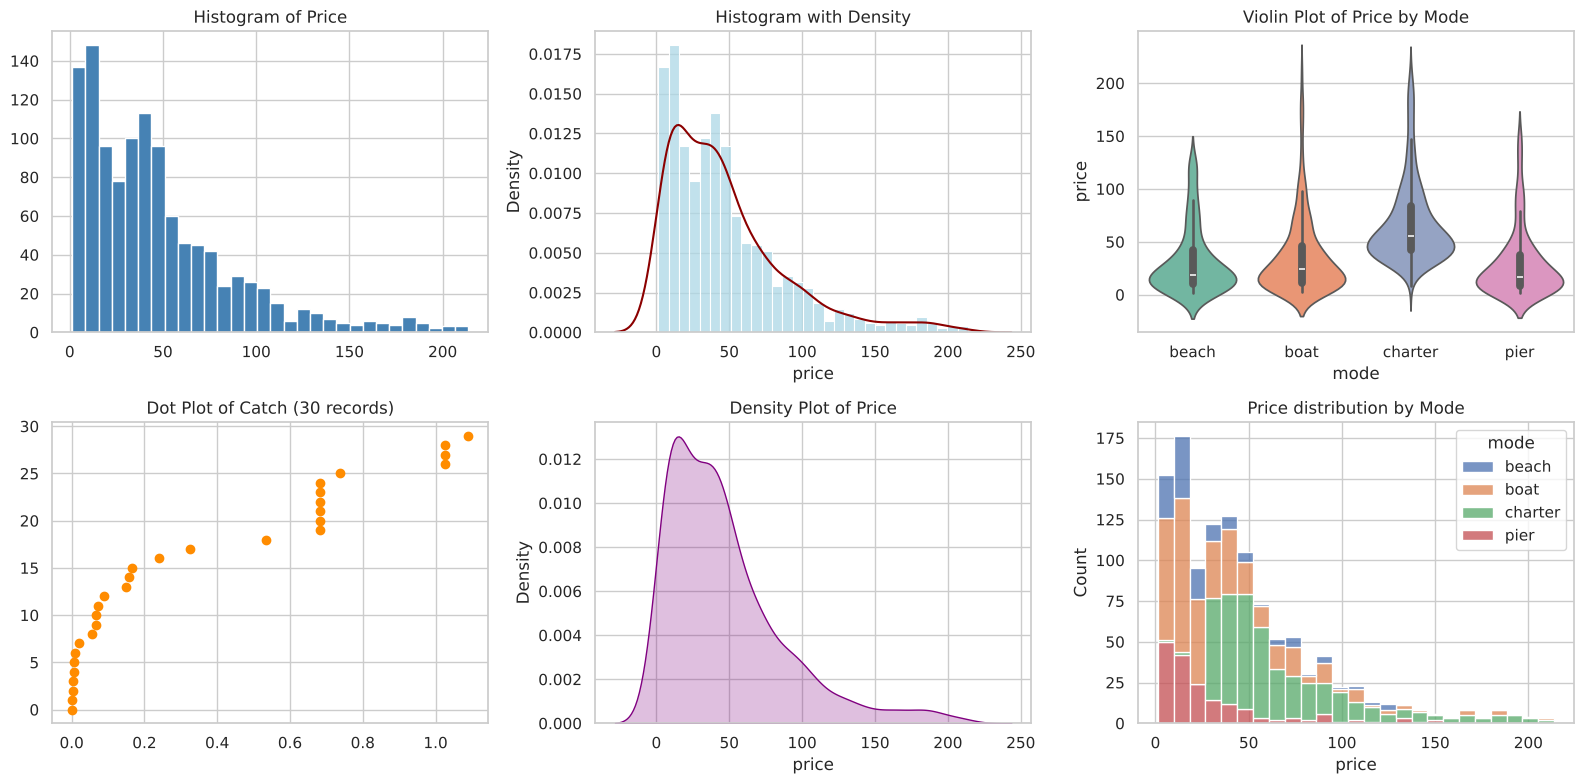

         count   mean  median    std
mode                                
beach      132  32.13   18.87  31.73
boat       406  36.62   24.33  37.44
charter    443  68.46   55.89  39.37
pier       177  29.54   16.77  32.48


In [ ]:
fig, ax = plt.subplots(2,3, figsize=(16,8))
# Q17 histogram, Q18 hist+density, Q19 violin
ax[0,0].hist(fish_no_out.price, bins=30, color="steelblue", edgecolor="white"); ax[0,0].set_title("Histogram of Price")
sns.histplot(fish_no_out.price, bins=30, stat="density", color="lightblue", ax=ax[0,1]); sns.kdeplot(fish_no_out.price, color="darkred", ax=ax[0,1]); ax[0,1].set_title("Histogram with Density")
sns.violinplot(data=fish_no_out, x="mode", y="price", palette="Set2", inner="box", ax=ax[0,2]); ax[0,2].set_title("Violin Plot of Price by Mode")
# Q20 dot plot (30-sample strip)
small = fish_no_out.sample(30, random_state=1); ax[1,0].plot(np.sort(small.catch), np.arange(30), "o", color="darkorange"); ax[1,0].set_title("Dot Plot of Catch (30 records)")
# Q29 density, Q30 hist by mode
sns.kdeplot(fish_no_out.price, fill=True, color="purple", ax=ax[1,1]); ax[1,1].set_title("Density Plot of Price")
sns.histplot(data=fish_no_out, x="price", hue="mode", bins=25, multiple="stack", ax=ax[1,2]); ax[1,2].set_title("Price distribution by Mode")
plt.tight_layout(); plt.show()
print(fish_no_out.groupby("mode")["price"].agg(["count","mean","median","std"]).round(2))

         Frequency  Proportion  Percentage
mode                                      
beach          132      0.1140       11.40
boat           406      0.3506       35.06
charter        443      0.3826       38.26
pier           177      0.1528       15.28


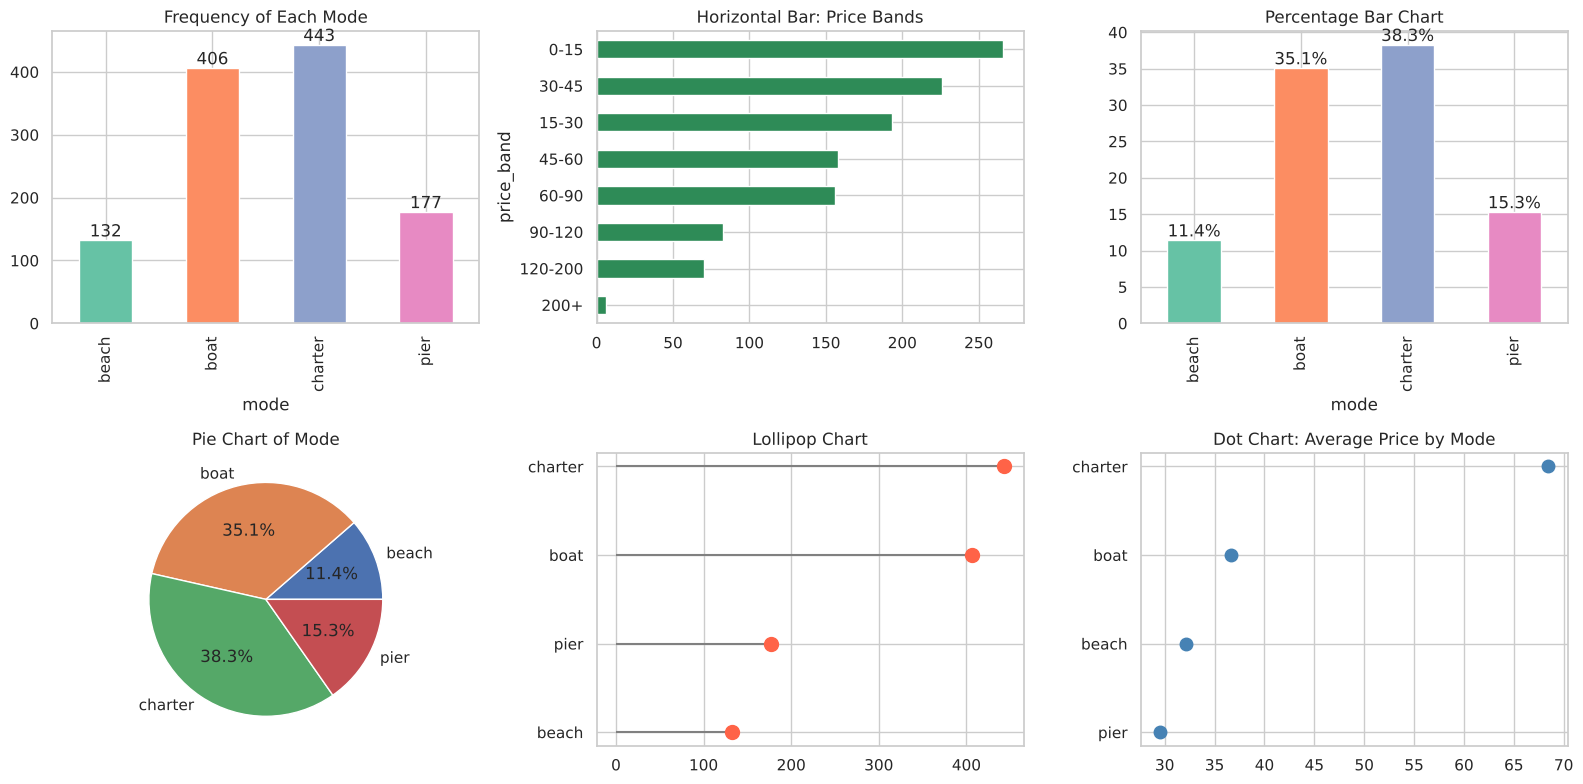

In [ ]:
# Q21-Q28 categorical charts
freq = fish_no_out["mode"].value_counts().sort_index(); prop = pd.DataFrame({"Frequency":freq, "Proportion":(freq/freq.sum()).round(4), "Percentage":(100*freq/freq.sum()).round(2)}); print(prop)
fish_no_out["price_band"] = pd.cut(fish_no_out.price, [0,15,30,45,60,90,120,200,np.inf], labels=["0-15","15-30","30-45","45-60","60-90","90-120","120-200","200+"])
fig, ax = plt.subplots(2,3, figsize=(16,8))
freq.plot.bar(ax=ax[0,0], color=sns.color_palette("Set2")); ax[0,0].set_title("Frequency of Each Mode"); ax[0,0].bar_label(ax[0,0].containers[0])
fish_no_out.price_band.value_counts().sort_values().plot.barh(ax=ax[0,1], color="seagreen"); ax[0,1].set_title("Horizontal Bar: Price Bands")
(prop.Percentage).plot.bar(ax=ax[0,2], color=sns.color_palette("Set2")); ax[0,2].set_title("Percentage Bar Chart"); ax[0,2].bar_label(ax[0,2].containers[0], fmt="%.1f%%")
ax[1,0].pie(freq, labels=freq.index, autopct="%.1f%%"); ax[1,0].set_title("Pie Chart of Mode")
f_sorted = freq.sort_values(); ax[1,1].hlines(f_sorted.index, 0, f_sorted.values, color="grey"); ax[1,1].plot(f_sorted.values, f_sorted.index, "o", color="tomato", ms=10); ax[1,1].set_title("Lollipop Chart")
mp = fish_no_out.groupby("mode")["price"].mean().sort_values(); ax[1,2].plot(mp.values, mp.index, "o", color="steelblue", ms=9); ax[1,2].set_title("Dot Chart: Average Price by Mode")
plt.tight_layout(); plt.show()

# Assessment 4 — Data Transformations

## Q2. Data transformations
Create a numeric vector named after your first name (10 values, first = last four digits of Reg No), then apply: (1) range normalization to [-3,+3], [-1,+1], [0,1]; (2) Z-score; (3) decimal scaling.

In [ ]:
# Assessment 4 — Data Transformations on a user-defined vector
# Vector named after first name; first value = last four digits of Reg No (0027), then 9 integers
Revanth = np.array([27, 15, 32, 48, 56, 72, 84, 96, 110, 125], dtype=float)
print("\nOriginal Vector"); print(Revanth.astype(int))

# 1. Normalization to a given range
def normalize(x, new_min, new_max):
    return (x - x.min()) / (x.max() - x.min()) * (new_max - new_min) + new_min

np.set_printoptions(precision=7, suppress=True, linewidth=120)
print("\nNormalization [-3, +3]"); print(normalize(Revanth, -3, 3))
print("\nNormalization [-1, +1]"); print(normalize(Revanth, -1, 1))
print("\nMin-Max Normalization [0, 1]"); print(normalize(Revanth, 0, 1))

# 2. Z-score transformation (sample SD, as R's sd())
z_score = (Revanth - Revanth.mean()) / Revanth.std(ddof=1)
print("\nZ-Score Transformation"); print(z_score)

# 3. Decimal scaling normalization
j = len(str(int(np.abs(Revanth).max())))
decimal_scaling = Revanth / 10**j
print("\nDecimal Scaling Normalization (j = %d)" % j); print(decimal_scaling)


Original Vector
[ 27  15  32  48  56  72  84  96 110 125]

Normalization [-3, +3]
[-2.3454545 -3.        -2.0727273 -1.2       -0.7636364  0.1090909  0.7636364  1.4181818  2.1818182  3.       ]

Normalization [-1, +1]
[-0.7818182 -1.        -0.6909091 -0.4       -0.2545455  0.0363636  0.2545455  0.4727273  0.7272727  1.       ]

Min-Max Normalization [0, 1]
[0.1090909 0.        0.1545455 0.3       0.3727273 0.5181818 0.6272727 0.7363636 0.8636364 1.       ]

Z-Score Transformation
[-1.0651712 -1.3887676 -0.9303394 -0.4988777 -0.2831468  0.148315   0.4719113  0.7955076  1.1730367  1.5775321]

Decimal Scaling Normalization (j = 3)
[0.027 0.015 0.032 0.048 0.056 0.072 0.084 0.096 0.11  0.125]


# Assessment 5 — Multivariate Visualisation

Numerical: ['rownames', 'price', 'catch', 'pbeach', 'ppier', 'pboat', 'pcharter', 'cbeach', 'cpier', 'cboat', 'ccharter', 'income']
Categorical: ['mode', 'income_level']


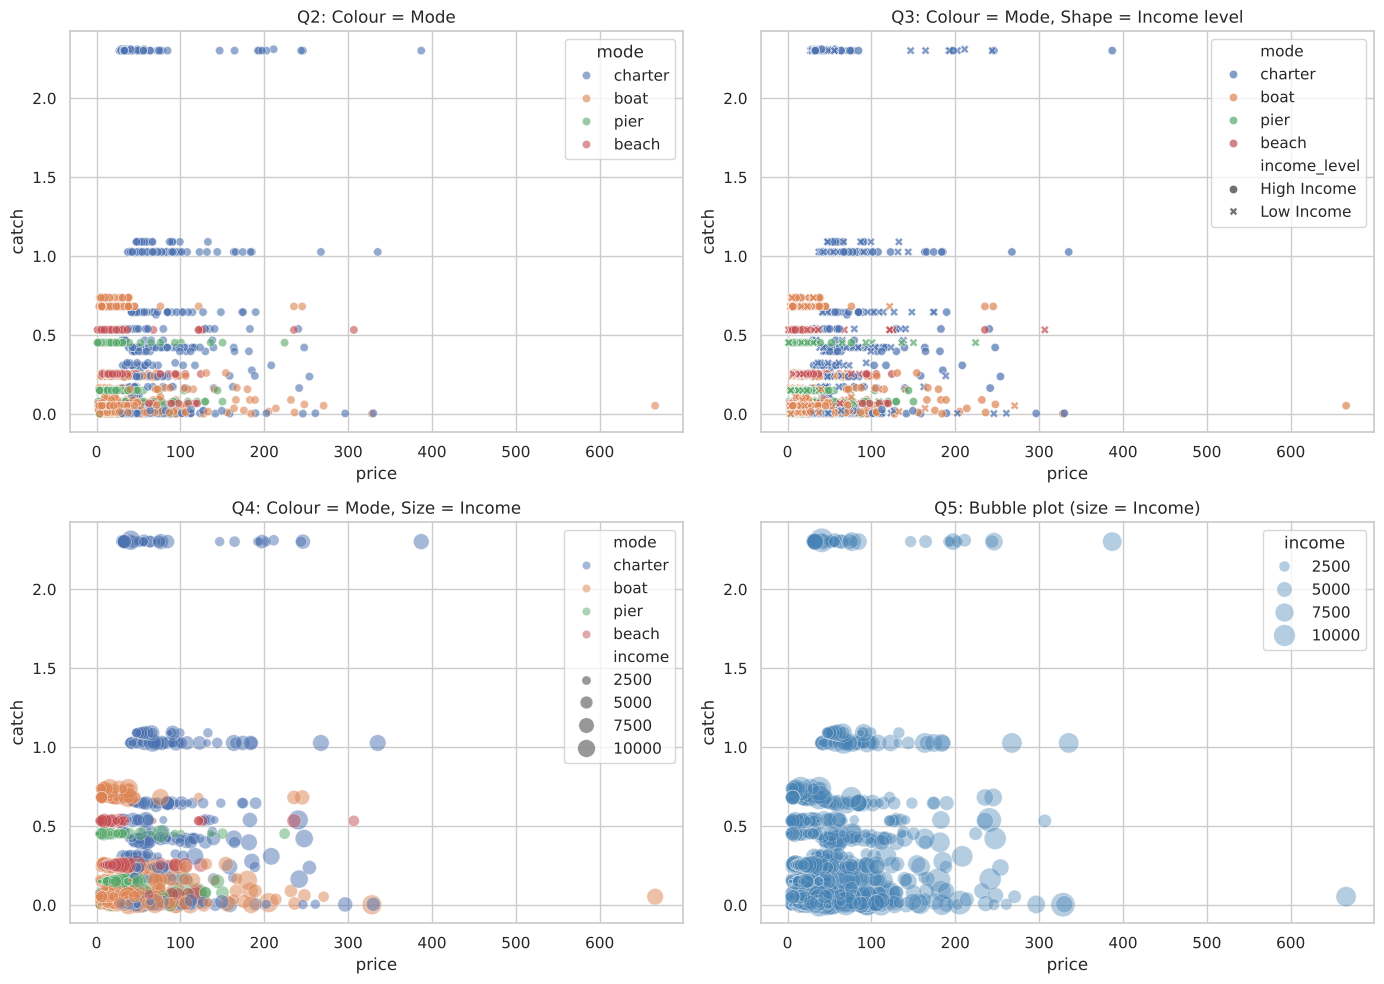

In [ ]:
fishing["income_level"] = np.where(fishing.income > fishing.income.median(), "High Income", "Low Income")
num_vars = fishing.select_dtypes("number").columns.tolist(); cat_vars = fishing.select_dtypes("object").columns.tolist()
print("Numerical:", num_vars); print("Categorical:", cat_vars)
fig, ax = plt.subplots(2,2, figsize=(14,10))
sns.scatterplot(data=fishing, x="price", y="catch", hue="mode", alpha=.6, ax=ax[0,0]); ax[0,0].set_title("Q2: Colour = Mode")
sns.scatterplot(data=fishing, x="price", y="catch", hue="mode", style="income_level", alpha=.7, ax=ax[0,1]); ax[0,1].set_title("Q3: Colour = Mode, Shape = Income level")
sns.scatterplot(data=fishing, x="price", y="catch", hue="mode", size="income", sizes=(10,200), alpha=.5, ax=ax[1,0]); ax[1,0].set_title("Q4: Colour = Mode, Size = Income")
sns.scatterplot(data=fishing, x="price", y="catch", size="income", sizes=(10,300), alpha=.4, color="steelblue", ax=ax[1,1]); ax[1,1].set_title("Q5: Bubble plot (size = Income)")
plt.tight_layout(); plt.show()

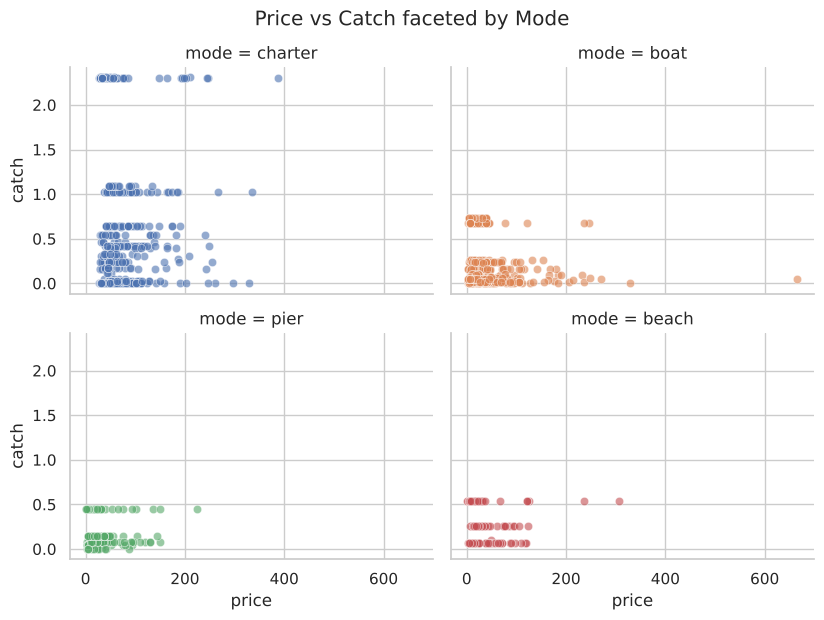

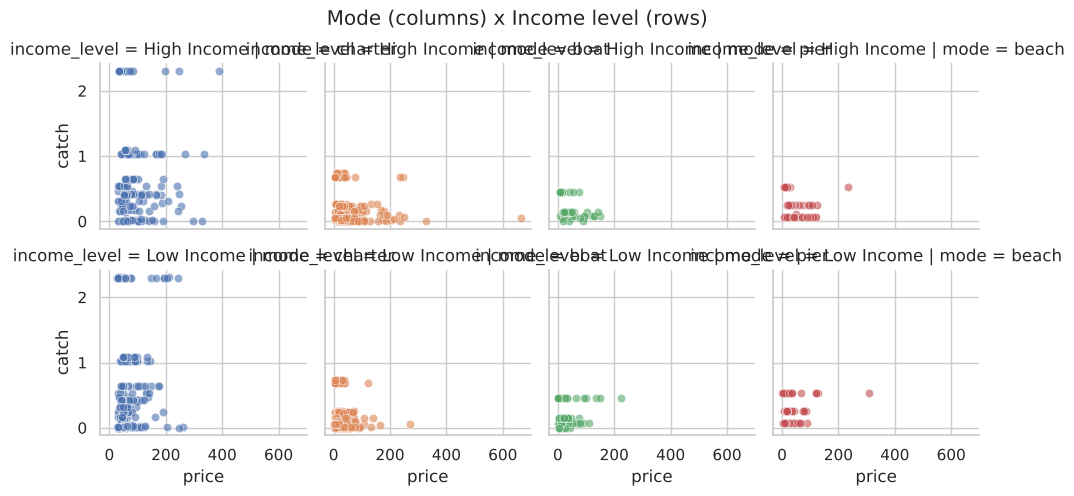

In [ ]:
# Q6 facet_wrap, Q7 facet_grid
g = sns.FacetGrid(fishing, col="mode", col_wrap=2, hue="mode", height=3, aspect=1.4); g.map_dataframe(sns.scatterplot, x="price", y="catch", alpha=.6); g.fig.suptitle("Price vs Catch faceted by Mode", y=1.03); plt.show()
g = sns.FacetGrid(fishing, row="income_level", col="mode", hue="mode", height=2.4); g.map_dataframe(sns.scatterplot, x="price", y="catch", alpha=.6); g.fig.suptitle("Mode (columns) x Income level (rows)", y=1.03); plt.show()

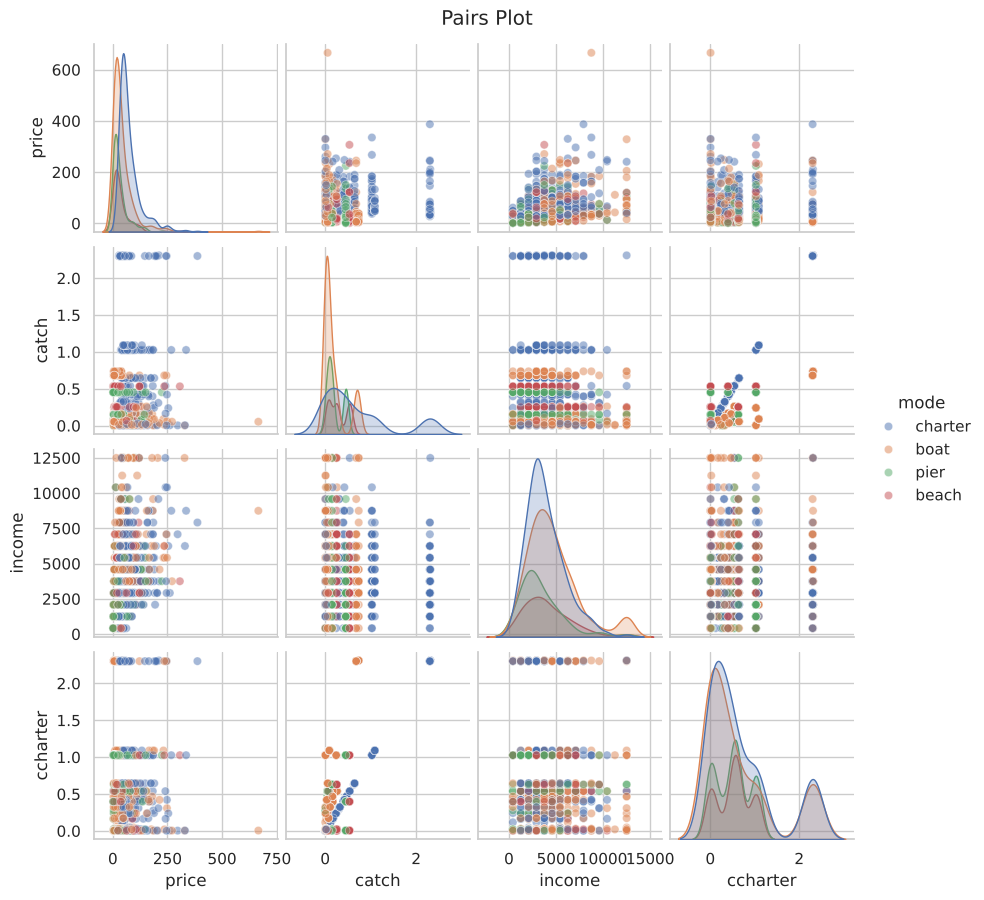

          price  catch  income  ccharter
price     1.000  0.107   0.315     -0.02
catch     0.107  1.000  -0.083      0.79
income    0.315 -0.083   1.000     -0.05
ccharter -0.020  0.790  -0.050      1.00


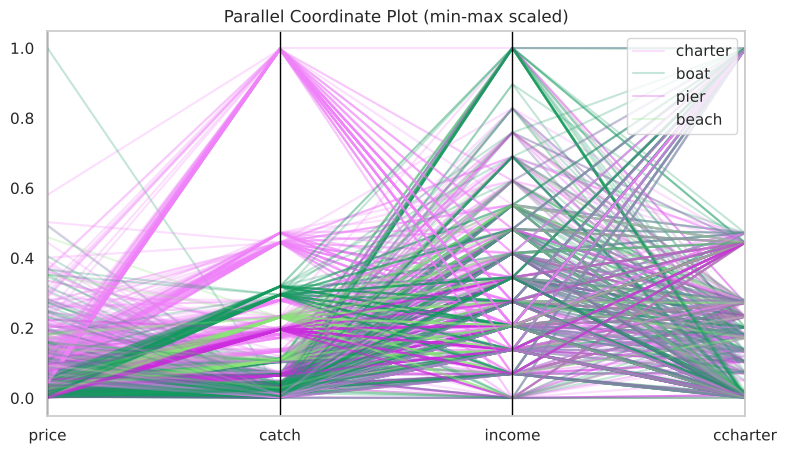

In [ ]:
# Q8 pairs plot, Q9 parallel coordinates
pair_vars = ["price","catch","income","ccharter"]
sns.pairplot(fishing, vars=pair_vars, hue="mode", plot_kws=dict(alpha=.5), height=2.2); plt.suptitle("Pairs Plot", y=1.02); plt.show()
print(fishing[pair_vars].corr().round(3))
from pandas.plotting import parallel_coordinates
pc = fishing[pair_vars].copy(); pc = (pc - pc.min())/(pc.max()-pc.min()); pc["mode"] = fishing["mode"]
plt.figure(figsize=(9,5)); parallel_coordinates(pc, "mode", alpha=.25); plt.title("Parallel Coordinate Plot (min-max scaled)"); plt.show()

# Assessment 6 — Time Series (Price series from block means)

[58.8785, 31.9885, 32.6165, 55.1335, 47.356] [25.517, 14.617, 19.719, 51.367, 31.1315]
Start: period 1-1, End: period 12-12, Frequency: 12, Length: 144
count    144.00
mean      51.46
std       32.92
min        9.29
25%       26.78
50%       39.89
75%       69.95
max      165.38
Name: price_block_mean, dtype: float64


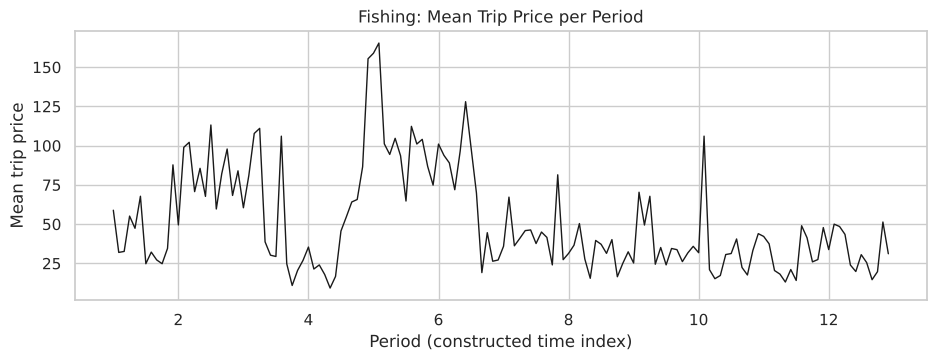

In [ ]:
# 144 blocks of 8 consecutive observations -> monthly series (12 'years' x 12 months)
n_blocks, block_size = 144, 8
price_sub = fishing["price"].values[: n_blocks*block_size]
block_mean = price_sub.reshape(n_blocks, block_size).mean(axis=1)
idx = pd.period_range("0001-01", periods=n_blocks, freq="M")
price_ts = pd.Series(block_mean, index=pd.RangeIndex(1, n_blocks+1), name="price_block_mean")
print(price_ts.head(5).round(4).tolist(), price_ts.tail(5).round(4).tolist())
print("Start: period 1-1, End: period 12-12, Frequency: 12, Length:", len(price_ts))
print(price_ts.describe().round(2))
plt.figure(figsize=(11,3.5)); plt.plot(np.arange(1, 145)/12 + 0.9167, block_mean, "k", lw=1); plt.title("Fishing: Mean Trip Price per Period"); plt.xlabel("Period (constructed time index)"); plt.ylabel("Mean trip price"); plt.show()

Seasonal indices: [  2.6088  22.8567   6.7335   0.3708  -9.1578  -4.1209  -5.5244   4.8818
  -7.762  -11.354   -5.4278   5.8955]


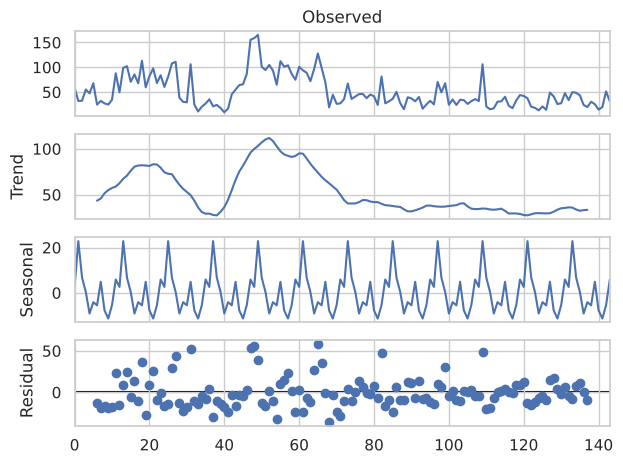

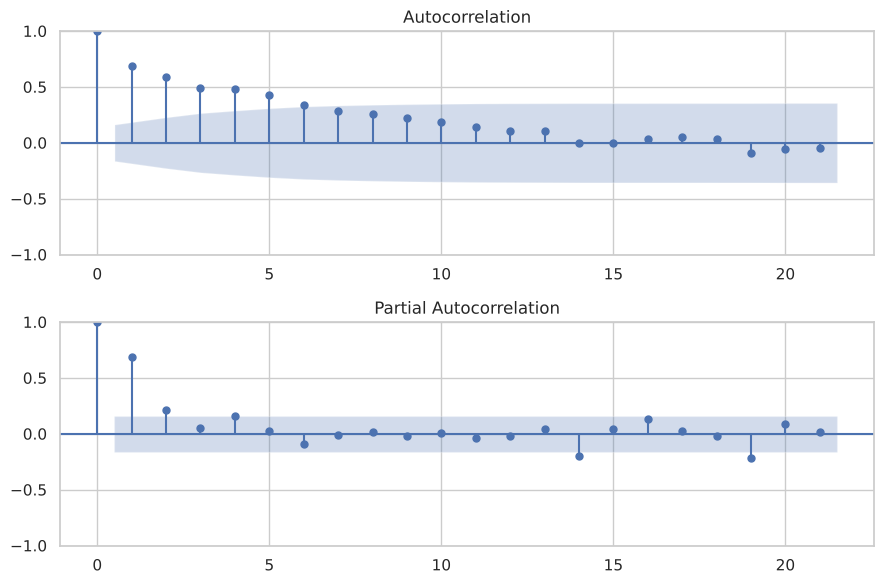

In [ ]:
# Q6-7 decomposition (additive, period 12)
decomp = seasonal_decompose(price_ts.values, model="additive", period=12)
print("Seasonal indices:", decomp.seasonal[:12].round(4))
decomp.plot(); plt.show()
# Q8 ACF / PACF
fig, ax = plt.subplots(2,1, figsize=(9,6)); plot_acf(price_ts, lags=21, ax=ax[0]); plot_pacf(price_ts, lags=21, ax=ax[1], method="ywm"); plt.tight_layout(); plt.show()

In [ ]:
# Q9-10 ARIMA model selection by AIC
cands = {"ARIMA(0,0,0)":(0,0,0),"ARIMA(1,0,0)":(1,0,0),"ARIMA(0,0,1)":(0,0,1),"ARIMA(2,0,0)":(2,0,0),"ARIMA(1,0,1)":(1,0,1)}
fits = {k: ARIMA(price_ts.values, order=o, trend="c").fit() for k,o in cands.items()}
print(pd.DataFrame({"model":list(fits), "AIC":[round(f.aic,3) for f in fits.values()]}))
best = min(fits, key=lambda k: fits[k].aic); fit = fits[best]; print("Best by AIC:", best); print(fit.summary())
print("RMSE:", np.sqrt(np.mean(fit.resid**2)))
print(acorr_ljungbox(fit.resid, lags=[12], return_df=True))

          model       AIC
0  ARIMA(0,0,0)  1417.989
1  ARIMA(1,0,0)  1327.863
2  ARIMA(0,0,1)  1368.074
3  ARIMA(2,0,0)  1323.232
4  ARIMA(1,0,1)  1321.817
Best by AIC: ARIMA(1,0,1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  144
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -656.909
Date:                Mon, 19 Oct 2026   AIC                           1321.817
Time:                        12:49:11   BIC                           1333.696
Sample:                             0   HQIC                          1326.644
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         50.7762     10

    forecast  lower   upper
0      37.82  -7.47   83.12
1      39.60 -11.00   90.19
2      41.13 -13.09   95.34
3      42.45 -14.31   99.20
4      43.59 -14.99  102.17
5      44.57 -15.33  104.47
6      45.42 -15.45  106.29
7      46.15 -15.43  107.73
8      46.78 -15.32  108.89
9      47.33 -15.16  109.82
10     47.80 -14.98  110.58
11     48.21 -14.78  111.20


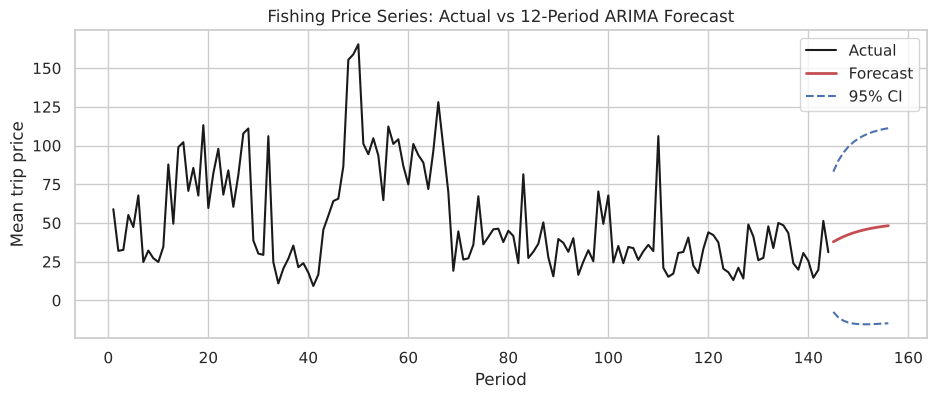

In [ ]:
# Q11-12 forecast next 12 periods with 95% CI
fc = fit.get_forecast(12); pred = fc.predicted_mean; ci = fc.conf_int(alpha=0.05)
print(pd.DataFrame({"forecast":pred, "lower":ci[:,0], "upper":ci[:,1]}).round(2))
t_act = np.arange(1, n_blocks+1); t_fc = np.arange(n_blocks+1, n_blocks+13)
plt.figure(figsize=(11,4)); plt.plot(t_act, price_ts.values, "k", label="Actual"); plt.plot(t_fc, pred, "r", lw=2, label="Forecast")
plt.plot(t_fc, ci[:,0], "b--", label="95% CI"); plt.plot(t_fc, ci[:,1], "b--")
plt.title("Fishing Price Series: Actual vs 12-Period ARIMA Forecast"); plt.xlabel("Period"); plt.ylabel("Mean trip price"); plt.legend(); plt.show()

# Assessment 7 — Descriptive Statistics, Tables & Correlation

       Statistic      Value
0           Mean    52.0820
1         Median    37.8960
2        Minimum     1.2900
3        Maximum   666.1100
4          Range   664.8200
5       Variance  2897.6656
6  Std Deviation    53.8300
7            IQR    51.6430
8       Skewness     3.1387
9       Kurtosis    19.1850
mode
beach      134
boat       418
charter    452
pier       178
Name: count, dtype: int64
mode
beach      0.1134
boat       0.3536
charter    0.3824
pier       0.1506
Name: count, dtype: float64


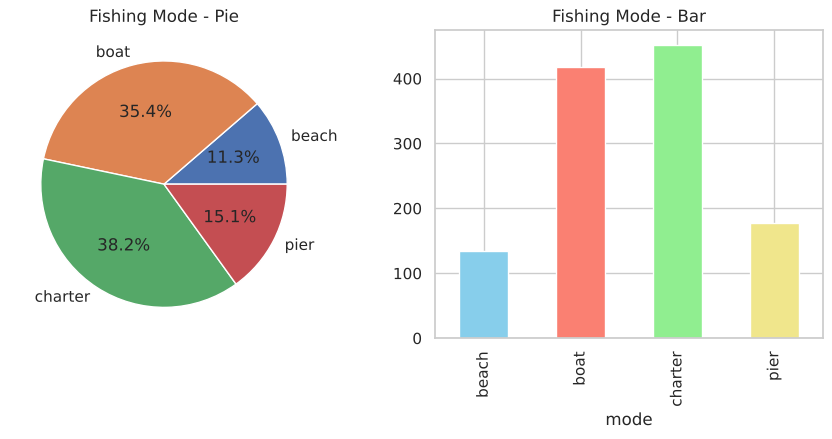

price
(0, 50]       746
(50, 100]     293
(100, 150]     79
(150, 200]     34
(200, 250]     19
(250, 300]      5
(300, 350]      4
(350, 400]      1
(400, 450]      0
(450, 500]      0
(500, 550]      0
(550, 600]      0
(600, 650]      0
(650, 700]      1
Name: count, dtype: int64


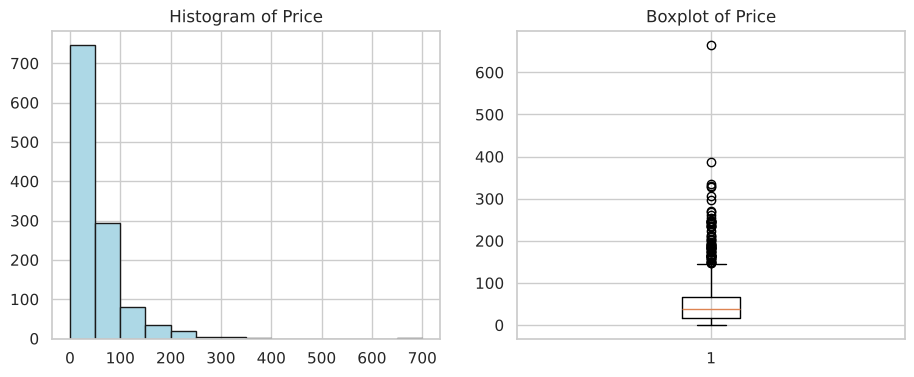

In [ ]:
p = fishing["price"]
price_summary = pd.DataFrame({"Statistic":["Mean","Median","Minimum","Maximum","Range","Variance","Std Deviation","IQR","Skewness","Kurtosis"],
    "Value":[p.mean(), p.median(), p.min(), p.max(), p.max()-p.min(), p.var(), p.std(), stats.iqr(p), stats.skew(p)*((len(p)-1)/len(p))**1.5, stats.kurtosis(p)*0+ (stats.kurtosis(p)+3)*((len(p)-1)/len(p))**2 - 3]}).round(4)
print(price_summary)
freq_table = fishing["mode"].value_counts().sort_index(); print(freq_table); print(freq_table.div(freq_table.sum()).round(4))
fig, ax = plt.subplots(1,2, figsize=(11,4)); ax[0].pie(freq_table, labels=freq_table.index, autopct="%.1f%%"); ax[0].set_title("Fishing Mode - Pie"); freq_table.plot.bar(ax=ax[1], color=["skyblue","salmon","lightgreen","khaki"]); ax[1].set_title("Fishing Mode - Bar"); plt.show()
bins = pd.cut(p, bins=np.arange(0,701,50)); print(bins.value_counts().sort_index())
fig, ax = plt.subplots(1,2, figsize=(11,4)); ax[0].hist(p, bins=np.arange(0,701,50), color="lightblue", edgecolor="k"); ax[0].set_title("Histogram of Price"); ax[1].boxplot(p); ax[1].set_title("Boxplot of Price"); plt.show()

income_level3  Low  Medium  High
mode                            
beach           59      34    41
boat           152     123   143
charter        213     128   111
pier           109      37    32
Row %:
 income_level3    Low  Medium   High
mode                               
beach          44.03   25.37  30.60
boat           36.36   29.43  34.21
charter        47.12   28.32  24.56
pier           61.24   20.79  17.98
Column %:
 income_level3    Low  Medium   High
mode                               
beach          11.07   10.56  12.54
boat           28.52   38.20  43.73
charter        39.96   39.75  33.94
pier           20.45   11.49   9.79


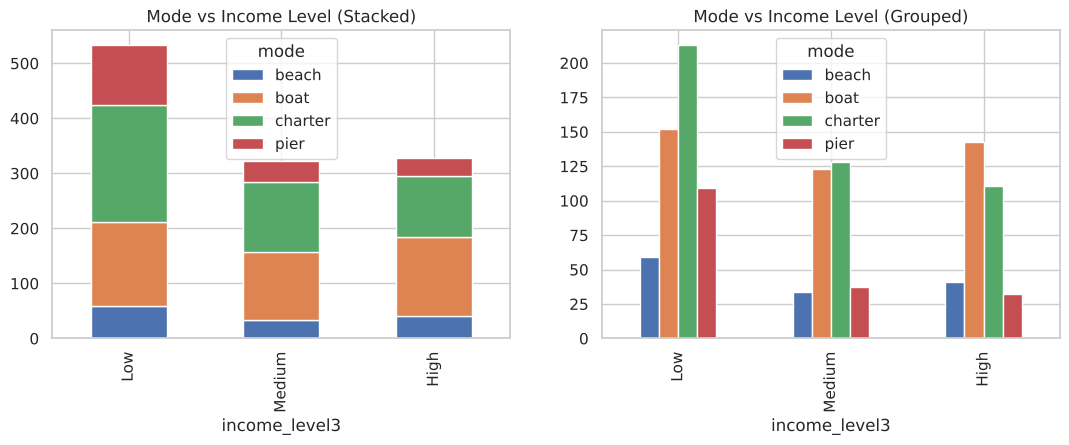

         mean_price  median_price   sd_price
mode                                        
beach     35.699493        19.308  43.094137
boat      41.606813        24.602  55.908063
charter   75.096942        56.870  52.519417
pier      30.571326        16.629  35.584416


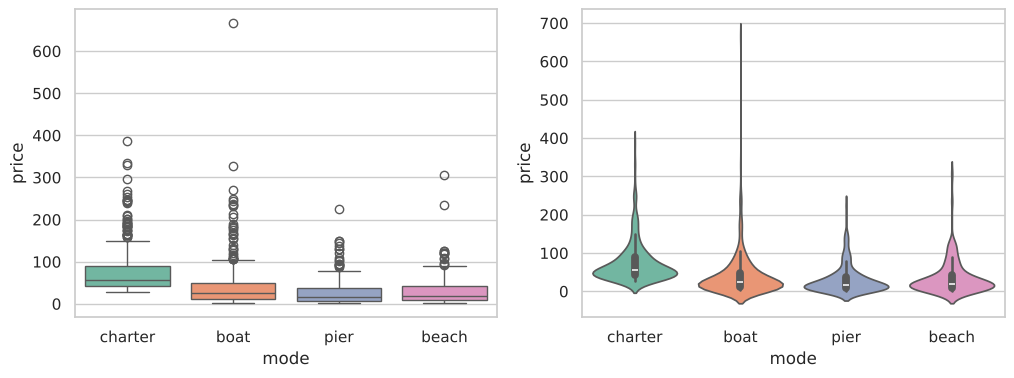

In [ ]:
# Q6-7 contingency tables
fishing["income_level3"] = pd.qcut(fishing.income, 3, labels=["Low","Medium","High"])
ct = pd.crosstab(fishing["mode"], fishing["income_level3"]); print(ct)
print("Row %:\n", (ct.div(ct.sum(axis=1), axis=0)*100).round(2)); print("Column %:\n", (ct.div(ct.sum(axis=0), axis=1)*100).round(2))
fig, ax = plt.subplots(1,2, figsize=(13,4)); ct.T.plot.bar(stacked=True, ax=ax[0], title="Mode vs Income Level (Stacked)"); ct.T.plot.bar(ax=ax[1], title="Mode vs Income Level (Grouped)"); plt.show()
# Q8 groupby stats
print(fishing.groupby("mode")["price"].agg(mean_price="mean", median_price="median", sd_price="std"))
# Q9 box + violin
fig, ax = plt.subplots(1,2, figsize=(12,4)); sns.boxplot(data=fishing, x="mode", y="price", palette="Set2", ax=ax[0]); sns.violinplot(data=fishing, x="mode", y="price", palette="Set2", ax=ax[1]); plt.show()

Pearson : 0.1069
Spearman: 0.0744


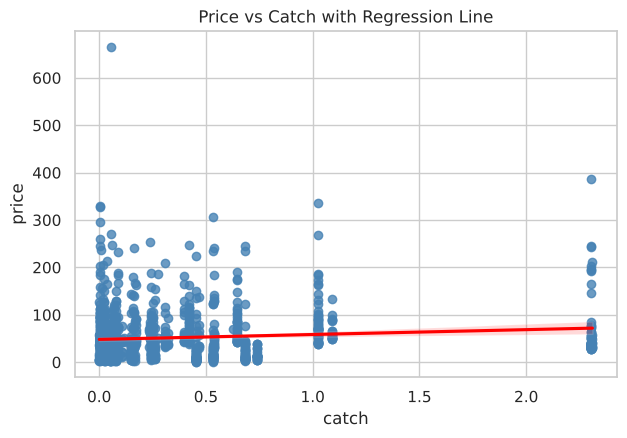

       mode income_level3  mean_price  sd_price
0     beach           Low       20.00     24.85
1     beach        Medium       40.53     55.12
2     beach          High       54.28     45.12
3      boat           Low       22.00     23.78
4      boat        Medium       37.97     42.69
5      boat          High       65.58     77.53
6   charter           Low       60.20     37.84
7   charter        Medium       75.29     41.48
8   charter          High      103.45     72.95
9      pier           Low       20.20     23.46
10     pier        Medium       40.74     49.51
11     pier          High       54.13     37.29


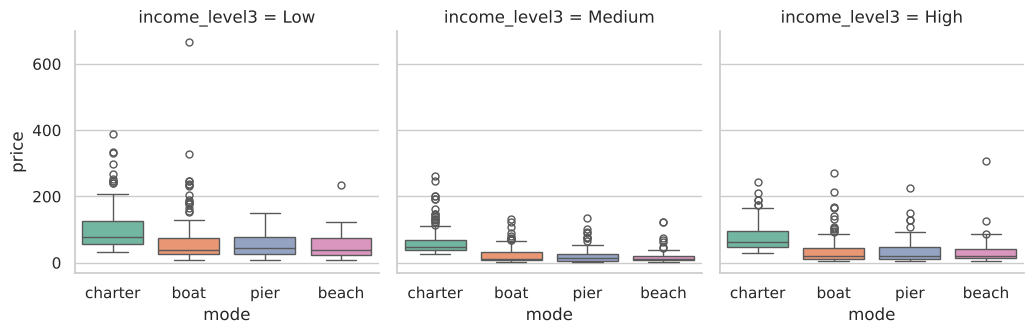

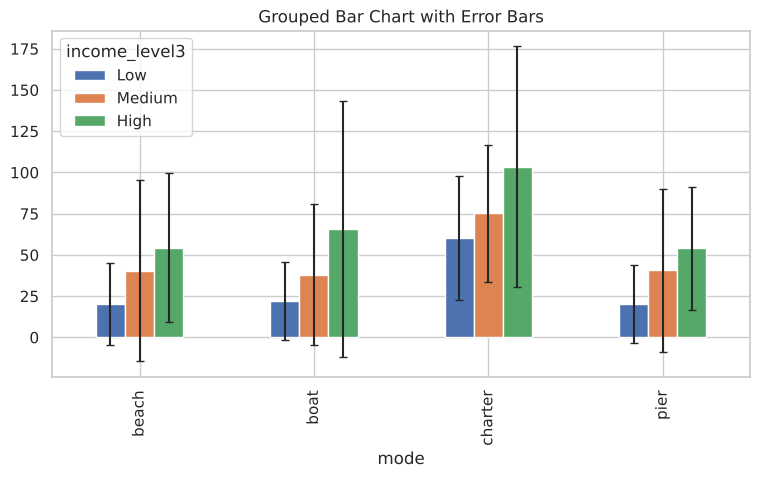

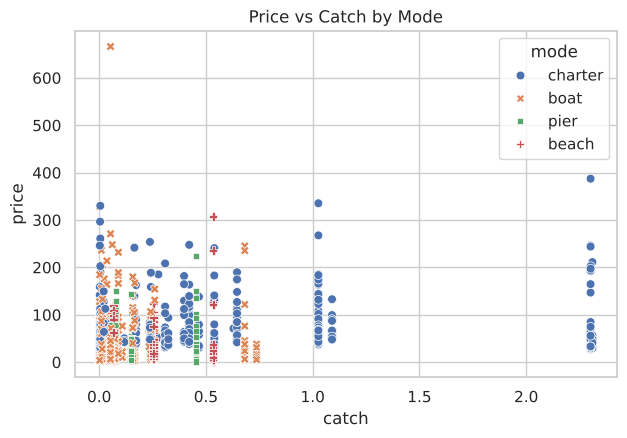

mode
beach     -0.0118
boat      -0.1128
charter   -0.0265
pier      -0.0732
dtype: float64
         price   catch  income
price   1.0000  0.1069  0.3153
catch   0.1069  1.0000 -0.0827
income  0.3153 -0.0827  1.0000


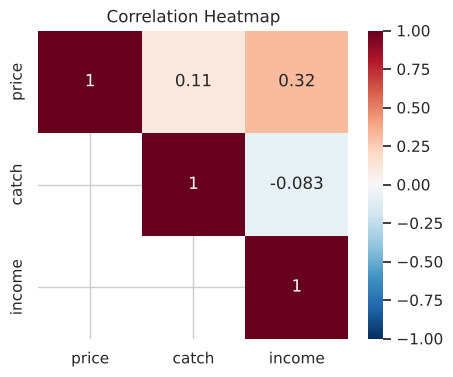

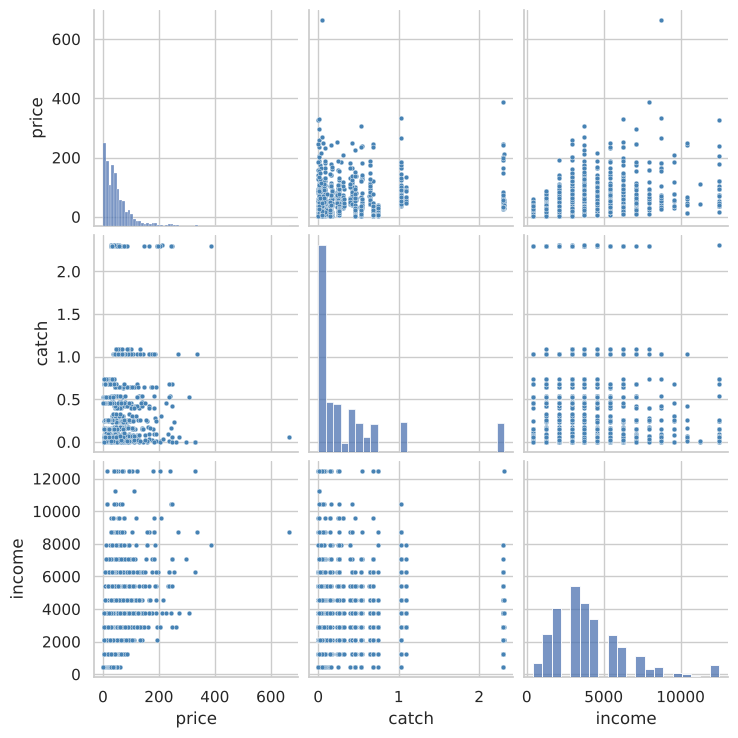

In [ ]:
# Q10 correlation + regression line
print("Pearson :", round(stats.pearsonr(fishing.price, fishing.catch)[0],4)); print("Spearman:", round(stats.spearmanr(fishing.price, fishing.catch)[0],4))
plt.figure(figsize=(7,4.5)); sns.regplot(data=fishing, x="catch", y="price", scatter_kws=dict(color="steelblue"), line_kws=dict(color="red")); plt.title("Price vs Catch with Regression Line"); plt.show()
# Q11 mean/SD by mode x income level + faceted box + error bars
agg11 = fishing.groupby(["mode","income_level3"])["price"].agg(mean_price="mean", sd_price="std").reset_index(); print(agg11.round(2))
sns.catplot(data=fishing, x="mode", y="price", col="income_level3", kind="box", palette="Set2", height=3.5); plt.show()
piv_m = agg11.pivot(index="mode", columns="income_level3", values="mean_price"); piv_s = agg11.pivot(index="mode", columns="income_level3", values="sd_price")
piv_m.plot.bar(yerr=piv_s, capsize=3, figsize=(9,4.5), title="Grouped Bar Chart with Error Bars"); plt.show()
# Q12 scatter by mode + per-mode correlation
plt.figure(figsize=(7,4.5)); sns.scatterplot(data=fishing, x="catch", y="price", hue="mode", style="mode", s=40); plt.title("Price vs Catch by Mode"); plt.show()
print(fishing.groupby("mode").apply(lambda d: d["price"].corr(d["catch"])).round(4))
# Q13-14 correlation heatmap + pairs
nv = fishing[["price","catch","income"]]; cm = nv.corr().round(4); print(cm)
plt.figure(figsize=(5,4)); sns.heatmap(cm, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, mask=np.tril(np.ones_like(cm, dtype=bool), -1)); plt.title("Correlation Heatmap"); plt.show()
sns.pairplot(nv, plot_kws=dict(color="steelblue", s=12)); plt.show()

# Assessment 8 — K-Means & Hierarchical Clustering

In [ ]:
num_data = fishing.drop(columns=["rownames"]).select_dtypes("number").drop(columns=["income_level3"], errors="ignore")
num_data = num_data[["price","catch","pbeach","ppier","pboat","pcharter","cbeach","cpier","cboat","ccharter","income"]]
scaler = StandardScaler(); scaled = scaler.fit_transform(num_data)   # note: sklearn uses ddof=0, R scale() uses ddof=1
scaled = (num_data - num_data.mean())/num_data.std(ddof=1); scaled_data = scaled.values   # match R's scale()
print(scaled.head().round(3))
km2 = KMeans(n_clusters=2, n_init=25, random_state=123).fit(scaled_data)
print("Sizes:", np.bincount(km2.labels_)); print(pd.DataFrame(km2.cluster_centers_, columns=num_data.columns).round(3))
tot_ss = ((scaled_data - scaled_data.mean(0))**2).sum(); print("between_SS/total_SS:", round(1 - km2.inertia_/tot_ss, 4))

   price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
0  2.431  0.267   0.526  0.526  1.637     1.551  -0.908 -0.698  0.424    -0.128   1.212
1 -0.326  0.139  -0.852 -0.852 -0.713    -0.784  -0.714 -0.730 -0.066    -0.230  -1.157
2 -0.515 -0.264   0.564  0.564 -0.493    -0.394   1.532  1.808  0.334     0.563  -0.142
3 -0.686 -0.554  -0.852 -0.852  0.011     0.009  -0.908 -0.520 -0.033    -0.128  -0.819
4 -0.196 -0.502   0.034  0.034 -0.219    -0.210  -0.908 -0.698 -0.300    -0.432   0.197
Sizes: [767 415]
   price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
0 -0.045 -0.391  -0.203 -0.203 -0.127    -0.147  -0.557 -0.573 -0.421    -0.453   0.036
1  0.083  0.722   0.376  0.376  0.235     0.271   1.030  1.060  0.777     0.838  -0.066
between_SS/total_SS: 0.2183


[12991.   10154.63  7837.34  6463.18  5530.55  4932.6   4455.6   4139.69
  3848.19  3648.88]


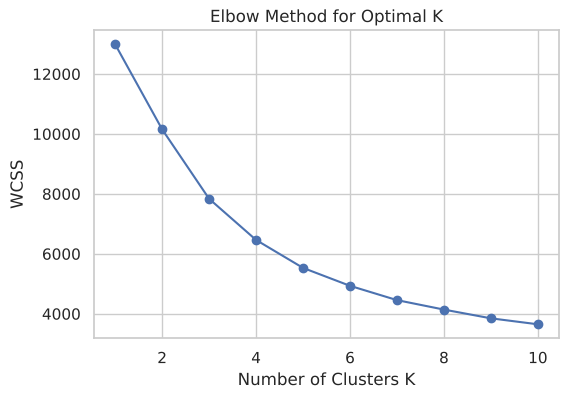

K=3 sizes: [710 337 135]
   price  catch  pbeach  ppier  pboat  pcharter  cbeach  cpier  cboat  ccharter  income
0 -0.169 -0.389  -0.292 -0.292 -0.241    -0.261  -0.615 -0.569 -0.419    -0.457  -0.049
1  0.433  0.012   0.708  0.708  0.677     0.742   1.269  1.234 -0.120     0.012   0.168
2 -0.193  2.017  -0.229 -0.229 -0.420    -0.479   0.067 -0.091  2.500     2.371  -0.162
between_SS/total_SS: 0.3967


In [ ]:
wcss = [KMeans(n_clusters=k, n_init=25, random_state=123).fit(scaled_data).inertia_ for k in range(1,11)]
print(np.round(wcss,2))
plt.figure(figsize=(6,4)); plt.plot(range(1,11), wcss, "bo-"); plt.xlabel("Number of Clusters K"); plt.ylabel("WCSS"); plt.title("Elbow Method for Optimal K"); plt.show()
km3 = KMeans(n_clusters=3, n_init=25, random_state=123).fit(scaled_data)   # K=3 from elbow
print("K=3 sizes:", np.bincount(km3.labels_)); print(pd.DataFrame(km3.cluster_centers_, columns=num_data.columns).round(3))
print("between_SS/total_SS:", round(1 - km3.inertia_/tot_ss, 4))

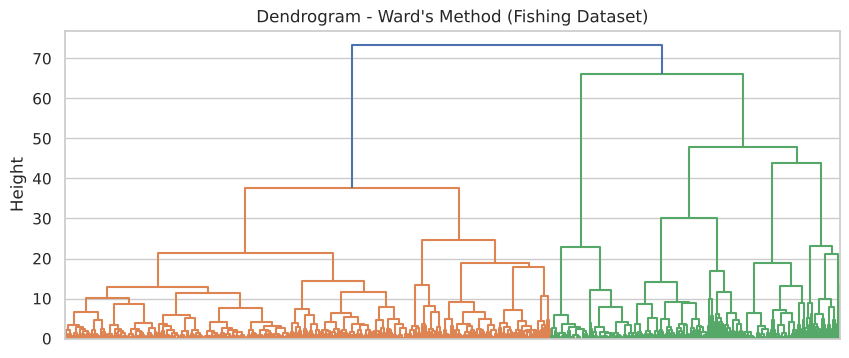

[3 1 3 1 1 3 1 1 1 1 1 3 1 1 1 1 1 1 1 1]
1    741
2    125
3    316
Name: count, dtype: int64


In [ ]:
# Hierarchical (Euclidean + Ward)
Z = linkage(scaled_data, method="ward", metric="euclidean")
plt.figure(figsize=(10,4)); dendrogram(Z, no_labels=True, color_threshold=Z[-2,2]+1e-6); plt.title("Dendrogram - Ward's Method (Fishing Dataset)"); plt.ylabel("Height"); plt.show()
clusters3 = fcluster(Z, t=3, criterion="maxclust"); print(clusters3[:20]); print(pd.Series(clusters3).value_counts().sort_index())

# Assessment 9 — Principal Component Analysis

                   PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10  PC11
Std dev         1.8520  1.6805  1.3574  1.2591  0.7922  0.5257  0.4421  0.4014  0.2371  0.0427   0.0
Prop. variance  0.3118  0.2567  0.1675  0.1441  0.0571  0.0251  0.0178  0.0146  0.0051  0.0002   0.0
Cumulative      0.3118  0.5685  0.7360  0.8801  0.9372  0.9623  0.9801  0.9947  0.9998  1.0000   1.0


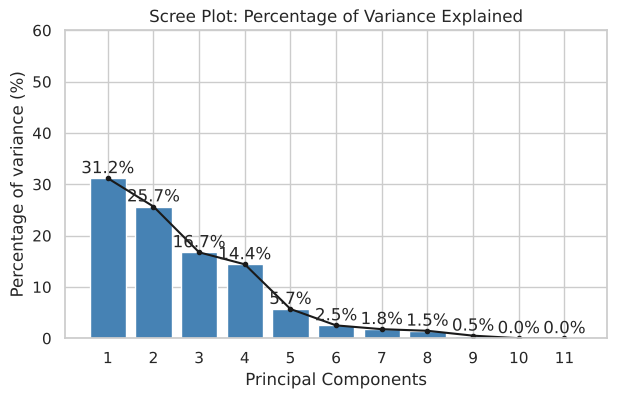

In [ ]:
data_scaled = scaled_data   # scaled numeric data from Assessment 8 (rownames removed)
pca = PCA().fit(data_scaled)
sd = np.sqrt(pca.explained_variance_); prop = pca.explained_variance_ratio_
print(pd.DataFrame({"Std dev":sd, "Prop. variance":prop, "Cumulative":prop.cumsum()}, index=[f"PC{i+1}" for i in range(len(sd))]).round(4).T)
# Scree plot (0-60 %)
plt.figure(figsize=(7,4)); b = plt.bar(range(1,len(prop)+1), prop*100, color="steelblue"); plt.plot(range(1,len(prop)+1), prop*100, "k.-")
for i,v in enumerate(prop*100): plt.text(i+1, v+1, f"{v:.1f}%", ha="center")
plt.ylim(0,60); plt.xlabel("Principal Components"); plt.ylabel("Percentage of variance (%)"); plt.title("Scree Plot: Percentage of Variance Explained"); plt.xticks(range(1,len(prop)+1)); plt.show()

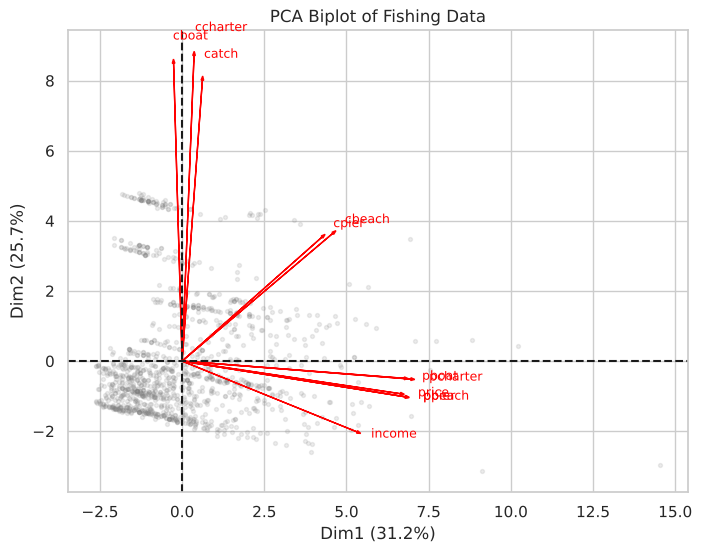

      PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10  PC11
0  2.5740 -0.5450  1.6460 -2.1057 -0.4686  0.0080  0.4284  0.0376 -0.3533  0.0121  -0.0
1 -2.1147 -0.0959  0.3236 -0.1069 -0.7238  0.0587 -0.0487 -0.0422 -0.1041 -0.0262   0.0
2  0.6994  1.1274 -1.4382  1.7584  0.3684 -0.2981  0.5067  0.0311  0.1795  0.0078  -0.0
3 -1.5690 -0.4440  0.9264  0.0407  0.0804 -0.5571 -0.1772 -0.3799 -0.0146  0.0206  -0.0
4 -0.5943 -1.0327 -0.1262 -0.6923  0.1230 -0.1684 -0.0477 -0.2173 -0.0603  0.0246  -0.0
5  1.3730  0.4506 -1.5188  1.5793 -0.0688  0.3980  0.6646  0.1099 -0.2459  0.0421  -0.0


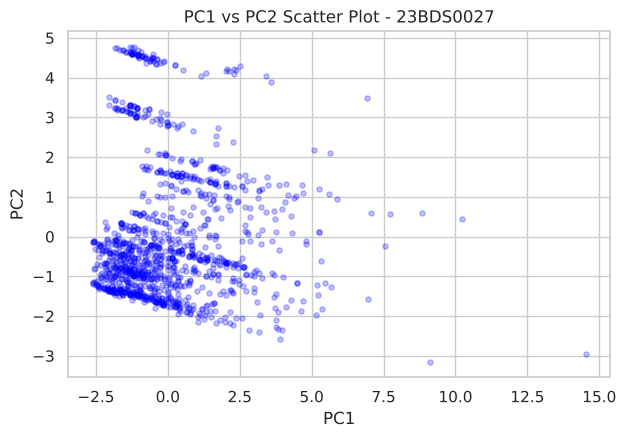

In [ ]:
scores = pca.transform(data_scaled); pca_scores = pd.DataFrame(scores, columns=[f"PC{i+1}" for i in range(scores.shape[1])])
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
# Biplot
fig, ax = plt.subplots(figsize=(8,6)); ax.scatter(scores[:,0], scores[:,1], s=8, c="grey", alpha=.15)
scale = np.abs(scores[:,:2]).max() / np.abs(loadings[:,:2]).max() * 0.6
for i, name in enumerate(num_data.columns):
    ax.arrow(0,0, loadings[i,0]*scale, loadings[i,1]*scale, color="red", head_width=.08); ax.text(loadings[i,0]*scale*1.08, loadings[i,1]*scale*1.08, name, color="red", fontsize=9)
ax.axhline(0, ls="--", c="k"); ax.axvline(0, ls="--", c="k"); ax.set_xlabel(f"Dim1 ({prop[0]*100:.1f}%)"); ax.set_ylabel(f"Dim2 ({prop[1]*100:.1f}%)"); ax.set_title("PCA Biplot of Fishing Data"); plt.show()
print(pca_scores.head(6).round(4))
plt.figure(figsize=(7,4.5)); plt.scatter(pca_scores.PC1, pca_scores.PC2, c="blue", marker="o", alpha=.25, s=14); plt.title("PC1 vs PC2 Scatter Plot - 23BDS0027"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()